In [31]:
import pandas as pd
import sqlite3
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score

In [2]:
connection=sqlite3.connect('../ecommerce.db')
customers=pd.read_csv(
    '../data/olist_customers_dataset.csv', 
    encoding='latin1')

orders=pd.read_csv(
    '../data/olist_orders_dataset.csv',
    encoding='latin1'

)

order_items=pd.read_csv(
    '../data/olist_order_items_dataset.csv',
    encoding='latin1'
)
pyamets=pd.read_csv(
    '../data/olist_order_payments_dataset.csv',
    encoding='latin1'
)

ml_df=pd.read_sql_query('''WITH first_order AS (
    SELECT 
        c.customer_id,
        c.customer_unique_id,
        o.order_id AS first_order_id,
        o.order_purchase_timestamp AS first_order_date,

        ROW_NUMBER() OVER (
            PARTITION BY c.customer_unique_id
            ORDER BY o.order_purchase_timestamp
        ) AS order_rank

    FROM orders AS o
    JOIN customers AS c 
        ON c.customer_id = o.customer_id
),

first_order_features AS (
    SELECT 
        fo.customer_unique_id,
        fo.first_order_id,
        fo.first_order_date,

        SUM(oi.price) AS first_order_value,
        COUNT(oi.order_item_id) AS first_order_items,
        SUM(oi.freight_value) AS first_order_freight

    FROM first_order AS fo

    JOIN order_items AS oi 
        ON oi.order_id = fo.first_order_id

    WHERE fo.order_rank = 1

    GROUP BY 
        fo.customer_unique_id,
        fo.first_order_id,
        fo.first_order_date
),

payment_features AS (
    SELECT 
        fo.first_order_id,

        SUM(p.payment_value) AS first_order_payment,
        MAX(p.payment_installments) AS first_order_installments

    FROM first_order AS fo

    JOIN payments AS p 
        ON p.order_id = fo.first_order_id

    WHERE fo.order_rank = 1

    GROUP BY fo.first_order_id
),
repeat_behavior as (
    select 
        fo.customer_unique_id,
        MAX(
            case 
                when julianday(o.order_purchase_timestamp)-julianday(fo.first_order_date) > 0 and 
                julianday(o.order_purchase_timestamp)-julianday(fo.first_order_date) <= 180 
                then 1
                else 0 
            END
    ) as repeat_customer
from first_order as fo 

LEFT JOIN customers AS c
    ON c.customer_unique_id = fo.customer_unique_id

left join orders as o on o.customer_id=c.customer_id
where fo.order_rank=1

group by fo.customer_unique_id
),
eligible_customers AS (
    SELECT
        rb.customer_unique_id,
        rb.repeat_customer
    FROM repeat_behavior AS rb
    JOIN first_order_features AS fof
        ON fof.customer_unique_id = rb.customer_unique_id
    WHERE julianday(
        (SELECT MAX(order_purchase_timestamp) FROM orders)
    ) - julianday(fof.first_order_date) >= 180
),
ml_dataset AS (
    SELECT
        fof.customer_unique_id,
        fof.first_order_id,
        fof.first_order_date,
        fof.first_order_value,
        fof.first_order_items,
        fof.first_order_freight,
        pf.first_order_payment,
        pf.first_order_installments,
        ec.repeat_customer
    FROM first_order_features AS fof

    JOIN payment_features AS pf
        ON pf.first_order_id = fof.first_order_id

    JOIN eligible_customers AS ec
        ON ec.customer_unique_id = fof.customer_unique_id
)
SELECT *
FROM ml_dataset;''', connection)

connection.close()

In [ ]:
ml_df.shape
ml_df.head()
ml_df.dtypes
ml_df.isna().sum()

In [3]:
features=ml_df[['first_order_value',
                'first_order_items',
                'first_order_freight',
                'first_order_payment',
                'first_order_installments']]
features.shape
target=ml_df['repeat_customer']
print(target.value_counts())
X_train, X_test, y_train, y_test= train_test_split(
    features, 
    target, 
    test_size=0.2,
    random_state=42,
    stratify=target)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


repeat_customer
0    66458
1     1859
Name: count, dtype: int64
(54653, 5)
(13664, 5)
(54653,)
(13664,)


In [4]:
model=LogisticRegression(
    max_iter=1000,
    random_state=42
    )
model.fit(X_train, y_train)
predictions=model.predict(X_test)
pd.Series(predictions).value_counts()

0    13663
1        1
Name: count, dtype: int64

In [ ]:
print(confusion_matrix(y_test, predictions))
print(accuracy_score(y_test, predictions))
print(precision_score(y_test, predictions))
print(recall_score(y_test, predictions))
print(f1_score(y_test, predictions))

array([[13292,     0],
       [  371,     1]])

In [ ]:
model2=LogisticRegression(max_iter=1000,
                         random_state=42,
                         class_weight='balanced')
model2.fit(X_train, y_train)
predictions=model2.predict(X_test)
pd.Series(predictions).value_counts()

In [ ]:
print(confusion_matrix(y_test, predictions))
print(accuracy_score(y_test, predictions))
print(precision_score(y_test, predictions))
print(recall_score(y_test, predictions))
print(f1_score(y_test, predictions))

In [19]:
scaler=StandardScaler()
X_train_scaled=scaler.fit(X_train).transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [20]:
model_scaled=LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

In [27]:
model_scaled.fit(X_train_scaled, y_train)
prediction_scaled=model_scaled.predict(X_test_scaled)
pd.Series(prediction_scaled).value_counts()
confusion_matrix(y_test, prediction_scaled)
print("Accuracy:", accuracy_score(y_test, prediction_scaled))
print("Precision:", precision_score(y_test, prediction_scaled))
print("Recall:", recall_score(y_test, prediction_scaled))
print("F1:", f1_score(y_test, prediction_scaled))

Accuracy: 0.6783518735362998
Precision: 0.038540949759119064
Recall: 0.45161290322580644
F1: 0.07102092580849714


In [ ]:
#Random Forest

In [5]:
model_rf=RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)
model_rf.fit(X_train, y_train)
rf_predictions=model_rf.predict(X_test)
print("Confusion_matrix:",confusion_matrix(y_test, rf_predictions))
print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(y_test, rf_predictions))
print("Recall:", recall_score(y_test, rf_predictions))
print("F1:", f1_score(y_test, rf_predictions))



Confusion_matrix: [[12356   936]
 [  336    36]]
Accuracy: 0.9069086651053864
Precision: 0.037037037037037035
Recall: 0.0967741935483871
F1: 0.05357142857142857


In [6]:
probabilities=model_rf.predict_proba(X_test)
print(probabilities[:,1])


[0.12581175 0.         0.9561938  ... 0.12561606 0.484607   0.        ]


In [28]:
probabilities_rf = model_rf.predict_proba(X_test)

rf_th_predictions = (probabilities_rf[:, 1] >= 0.06878306878306878).astype(int)

print("Confusion_matrix:", confusion_matrix(y_test, rf_th_predictions))
print("Accuracy:", accuracy_score(y_test, rf_th_predictions))
print("Precision:", precision_score(y_test, rf_th_predictions))
print("Recall:", recall_score(y_test, rf_th_predictions))
print("F1:", f1_score(y_test, rf_th_predictions))

Confusion_matrix: [[9793 3499]
 [ 239  133]]
Accuracy: 0.7264344262295082
Precision: 0.03661894273127753
Recall: 0.3575268817204301
F1: 0.06643356643356643


In [ ]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    probabilities_rf[:,1]
)

f1_scores = 2 * (precision * recall) / (precision + recall)
f1_scores = np.nan_to_num(f1_scores)
f1_scores = f1_scores[:-1]
best_index = f1_scores.argmax()

best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print("Best threshold:", best_threshold)
print("Best F1:", best_f1)

Best threshold: 0.06878306878306878
Best F1: 0.06643356643356643


C:\Users\ASUS\AppData\Local\Temp\ipykernel_9392\1662025390.py:6: RuntimeWarning: invalid value encountered in divide
  f1_scores = 2 * (precision * recall) / (precision + recall)


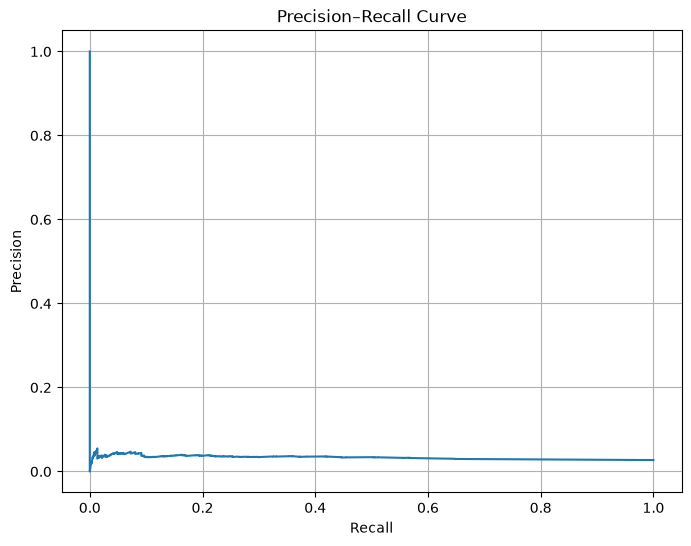

In [30]:
plt.figure(figsize=(8, 6))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.grid()

plt.show()

In [32]:
average_precision = average_precision_score(
    y_test,
    probabilities_rf[:, 1]
)

print(average_precision)

0.03281310458597699


In [33]:
feature_importance = model_rf.feature_importances_

print(feature_importance)

[0.27959306 0.014329   0.2793169  0.34998139 0.07677964]


In [34]:
features.corr()

,first_order_value,first_order_items,first_order_freight,first_order_payment,first_order_installments
first_order_value,1.000000,0.156230,0.416459,0.996378,0.313408
first_order_items,0.156230,1.000000,0.468315,0.193344,0.062834
first_order_freight,0.416459,0.468315,1.000000,0.492100,0.199042
first_order_payment,0.996378,0.193344,0.492100,1.000000,0.319015
first_order_installments,0.313408,0.062834,0.199042,0.319015,1.000000


In [35]:
features_reduced = ml_df[
    ['first_order_value',
     'first_order_items',
     'first_order_freight',
     'first_order_installments']
]

In [36]:
X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(
    features_reduced,
    target,
    test_size=0.2,
    random_state=42,
    stratify=target
)

In [37]:
model_rf_reduced = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)

model_rf_reduced.fit(X_train_red, y_train_red)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [40]:
probabilities_rf_reduced = model_rf_reduced.predict_proba(X_test_red)
average_precision_reduced = average_precision_score(
    y_test_red,
    probabilities_rf_reduced[:, 1]
)

print(average_precision_reduced)

0.032645029545733756
